# Stage 1: from ENSO and the IOD to monthly weather — the EOF–CCA model and its hindcast skill

Stage 1 turns a path of the two climate-mode indices into the weather that the three DEFINE-PH channels need:

$$\underbrace{\text{RONI}_t,\ \text{DMI}_t}_{\text{climate modes}} \;\longrightarrow\; \underbrace{W_{v,i,t}}_{\text{weather at ERA5 cell } i} \;\longrightarrow\; \underbrace{\textstyle\sum_i a_{i|r}\,W_{v,i,t}}_{\text{region } r,\ \text{with each section's weights}}$$

The main specification uses the RONI alone (`model.predictors` in `config.yaml`): adding the DMI does not improve the out-of-sample hindcasts (`scripts/helpers/analysis/dmi_analysis.py`). The RONI + DMI fit is kept as the variant `roni_dmi`, for the sensitivity and for stress scenarios that combine El Niño with a positive IOD; where this notebook shows a DMI effect, it comes from that variant.

This notebook explains each step of the model on the real fit and shows how well it predicts past weather (hindcast skill). It does not fit anything: the scripts do that, and the notebook reads what they wrote.

| Step | Script | Read here |
|---|---|---|
| ERA5 land cells, cropland and population weights, Table 2 fields | `scripts/01_prepare_inputs.py` | §2 |
| EOF–CCA per variable and month, cross-validation, skill | `scripts/03_fit_climate_model.py` | §3–7 |
| Scenario path from the C3S forecast; simulation | `scripts/helpers/make_path.py`, `scripts/04_simulate.py` | §8 |

Run `python scripts/run_all.py` first (from the project folder), then this notebook. The section numbers of the methodology refer to the agricultural note (v5) unless stated.

In [1]:
import json
import math
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, Normalize, ListedColormap, BoundaryNorm

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "stage1" / "engine.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from stage1 import config as C, engine as E, fit as F  # noqa: E402

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

cfg = C.load(os.environ.get("STAGE1_CONFIG") or ROOT / "config.yaml")
OUT = C.path(cfg, "outputs_dir")
D, VARS, EXTRA = F.load_data(cfg, refresh_indices=False)
MODELS = C.load_pickle(C.work(cfg, "models.pkl"), "scripts/03_fit_climate_model.py")
PRED = C.predictors(cfg)
# the RONI + DMI variant, for the DMI effects, when it has been fitted
_vcfg = C.load(os.environ.get("STAGE1_CONFIG") or ROOT / "config.yaml", "roni_dmi") if "roni_dmi" in (cfg.get("variants") or {}) else None
MODELS_JOINT = C.load_pickle(C.work(_vcfg, "models.pkl"), "") if _vcfg is not None and C.work(_vcfg, "models.pkl").exists() else None
DIAG = C.load_pickle(C.work(cfg, "fit_diagnostics.pkl"), "scripts/03_fit_climate_model.py")
VARS = [v for v in VARS if all((v, m) in MODELS for m in range(1, 13))]


def table(*parts):
    p = C.out_in(cfg, *parts)
    return pd.read_csv(p) if p.exists() else None


SEC = F.weight_sets(cfg)
WS_AGRI, WS_POP = SEC["agriculture"][0], SEC["electricity"][0]
SUMMARY = table("skill", "skill_summary.csv")
SK = {ws: table("skill", f"skill_{ws}.csv") for ws in F.all_weight_sets(cfg)}
CELLSK = table("skill", "skill_cells.csv")
HIND = table("skill", "hindcasts.csv")
PROB = table("skill", "probabilistic.csv")
JOINT = table("skill", "joint_check.csv")
CONFIGS = table("shared", "model_configs.csv")
COVER = table("shared", "weights_coverage.csv")
META = json.loads((OUT / "shared" / "run_metadata.json").read_text())
NESTED = META["03_fit_stage1"]["nested_cv"]
BEST = "nested" if NESTED else "plain"

LAT, LON, CELLS = D.weights["lat"], D.weights["lon"], D.cells
CLAT, CLON = LAT[CELLS // len(LON)], LON[CELLS % len(LON)]
GEO = {rs: D.weights["sets"][rs]["geometry"] for rs in ("r16", "r17")}
LONG = {k: v[0] for k, v in C.PREDICTANDS.items()}
UNITS = {k: v[1] for k, v in C.PREDICTANDS.items()}
MONTH = [pd.Timestamp(2000, m, 1).strftime("%b") for m in range(1, 13)]
print(f"{len(VARS)} variables x 12 months on {len(CELLS)} ERA5 cells; predictors: {' + '.join(PRED).upper()}; nested CV: {NESTED}"
      + ("; RONI + DMI variant loaded" if MODELS_JOINT is not None else ""))
print("weights:", {ws: META["03_fit_stage1"]["weights"][ws]["source"] + (" [FALLBACK]" if META["03_fit_stage1"]["weights"][ws]["fallback"] else "")
                   for ws in META["03_fit_stage1"]["weights"]})

10 variables x 12 months on 349 ERA5 cells; predictors: RONI; nested CV: True; RONI + DMI variant loaded
weights: {'r16_cropland': 'cropland km² (esa_cci_lc_2022_phl.nc)', 'r16_area': 'polygon overlap area', 'r17_population': 'population (phl_ppp_2020_1km_Aggregated_UNadj.tif)', 'r17_area': 'polygon overlap area'}


In [2]:
# Colours (reference palette of the dataviz guide): blue <-> red diverging with a grey midpoint, blue sequential
INK, INK2, MUTED, GRID, SURF, NODATA = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df", "#fcfcfb", "#e9e8e4"
S1, S2, S3 = "#2a78d6", "#eb6834", "#1baf7a"
BLUE_RED = LinearSegmentedColormap.from_list("bluered", ["#104281", "#3987e5", "#b7d3f6", "#f0efec", "#f6c3b8", "#e34948", "#8f1d1d"])
RED_BLUE = BLUE_RED.reversed()
BLUES = LinearSegmentedColormap.from_list("blues", ["#f0efec", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
mpl.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "text.color": INK, "axes.titlecolor": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9.5, "axes.titlesize": 10,
                     "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110})
XLIM, YLIM = (116.8, 126.8), (4.5, 21.2)
DLAT, DLON = abs(LAT[1] - LAT[0]), abs(LON[1] - LON[0])
LON_E = np.r_[LON - DLON / 2, LON[-1] + DLON / 2]
LAT_E = np.r_[LAT + DLAT / 2, LAT[-1] - DLAT / 2]


def frame(ax, title=None):
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM)
    ax.set_aspect(1 / math.cos(math.radians(12.5)))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=9)


def draw_regions(ax, values: pd.Series, cmap, norm, rs="r16", title=None):
    """Choropleth of a Series indexed by region code."""
    g = GEO[rs].copy()
    g["value"] = g["code"].map(values)
    GEO["r17"].plot(ax=ax, color=NODATA, edgecolor="white", linewidth=0.3)
    g[g["value"].notna()].plot(ax=ax, column="value", cmap=cmap, norm=norm, edgecolor="white", linewidth=0.35)
    frame(ax, title)


def draw_cells(ax, values, cmap, norm, title=None, rs="r17"):
    A = np.full(len(LAT) * len(LON), np.nan)
    A[CELLS] = values
    GEO[rs].plot(ax=ax, color=NODATA, edgecolor="none")
    ax.pcolormesh(LON_E, LAT_E, A.reshape(len(LAT), len(LON)), cmap=cmap, norm=norm, shading="flat")
    GEO[rs].boundary.plot(ax=ax, color="white", linewidth=0.4)
    frame(ax, title)


def cbar(fig, axes, cmap, norm, label, **kw):
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes, shrink=kw.pop("shrink", 0.6), pad=kw.pop("pad", 0.01), **kw)
    cb.set_label(label, color=INK2); cb.outline.set_visible(False)
    return cb

## 1 · Predictors: RONI and DMI

* **RONI**, the Relative Oceanic Niño Index (CPC), is the Niño-3.4 anomaly minus the tropical-mean anomaly, rescaled (Eq. 1). Because the warming of the whole tropics is removed, the index carries far less of the trend, so the slow warming of the Philippines is not attributed to ENSO. CPC publishes it as a centred 3-month mean.
* **DMI**, the Dipole Mode Index (NOAA PSL, HadISST), is the western minus the south-eastern equatorial Indian Ocean (Eq. 2). It is smoothed here to a centred 3-month mean, like the RONI.

**Which indices the model uses.** The main specification uses the RONI alone. Out of sample, adding the DMI improves no variable significantly and makes rainfall slightly worse; holding the RONI fixed, a positive IOD dries October–December by about a quarter to a third of the El Niño effect (`scripts/helpers/analysis/dmi_analysis.py`, `outputs/shared/analysis/dmi/`). The RONI + DMI model is kept as the variant `roni_dmi` (`python scripts/03_fit_climate_model.py --variant roni_dmi`).

For a target month the model uses the index in that month and, if it improves the cross-validated skill, also its value 1, 3 or 6 months earlier. Lags 3 and 6 reach back to the previous two 3-month seasons: from March to August the selection mostly picks the lag that points to the previous December–February, the ENSO peak (see `scripts/helpers/analysis/lag_analysis.py`). The grey line is the scenario path of §8, where it exists.

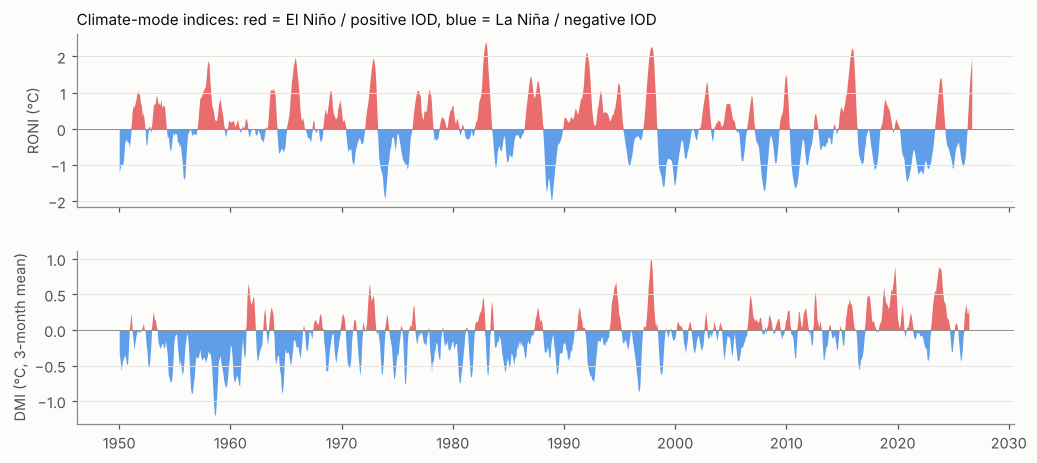

Correlation of RONI and DMI by calendar month, 1950–2025: Jan +0.04, Feb -0.20, Mar -0.25, Apr -0.14, May +0.03, Jun +0.19, Jul +0.28, Aug +0.37, Sep +0.45, Oct +0.49, Nov +0.48, Dec +0.32


In [3]:
P = D.P.loc["1950":]
path = table("shared", "path.csv")
fig, axes = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True, gridspec_kw={"hspace": 0.25})
for ax, k, lab in ((axes[0], "roni", "RONI (°C)"), (axes[1], "dmi", "DMI (°C, 3-month mean)")):
    s = P[k].dropna()
    ax.fill_between(s.index, 0, s.where(s > 0, 0), color="#e34948", lw=0, alpha=0.8)
    ax.fill_between(s.index, 0, s.where(s < 0, 0), color="#3987e5", lw=0, alpha=0.8)
    if path is not None:
        pth = path.set_index(pd.to_datetime(path["date"]))[k]
        ax.plot(pth.index, pth.values, color=INK2, lw=1.6)
        ax.annotate("path", (pth.index[-1], pth.values[-1]), xytext=(4, 0), textcoords="offset points", color=INK2, fontsize=8, va="center")
    ax.axhline(0, color=MUTED, lw=0.6)
    ax.set_ylabel(lab)
    ax.grid(axis="x", visible=False)
axes[0].set_title("Climate-mode indices: red = El Niño / positive IOD, blue = La Niña / negative IOD")
plt.show()
cc = pd.Series({m: P[P.index.month == m][["roni", "dmi"]].corr().iloc[0, 1] for m in range(1, 13)}, index=range(1, 13))
print("Correlation of RONI and DMI by calendar month, 1950–2025:", ", ".join(f"{MONTH[m - 1]} {v:+.2f}" for m, v in cc.items()))

The two indices are correlated in boreal autumn (El Niño tends to come with a positive IOD), and hardly from January to June. This is part of why the DMI adds little: in the autumn much of its signal is already carried by the RONI. The path still holds both, from the same forecast (§3.5), because the RONI + DMI variant needs them. In that variant the CCA handles the correlation: it finds the combinations of the two indices that best predict the weather.

## 2 · Predictands: the Table 2 variables at the ERA5 cells

**Cells.** The monthly variables of Table 2 come from ERA5 at 0.25° (about 28 km). A cell is kept when its ERA5 land fraction is at least 0.5 (§3.3.2); cells without soil water in ERA5, which its land model treats as sea, are dropped as well. Each kept cell is one column of the model, so the model sees the spatial detail within regions (coasts, mountains, the windward and leeward sides of the monsoons).

**Weights.** The cell values are averaged to regions only at the end. Each section uses its own weights, applied to the same model:

* **agriculture**: cropland area in each cell–region piece (Eq. 7), for the 16 regions;
* **electricity and labour**: population, for the 16 regions plus NCR;
* **area** as a sensitivity check.

The left map shows which region holds most of each cell's population. The other two show each cell's weight in its region, for cropland and for population.

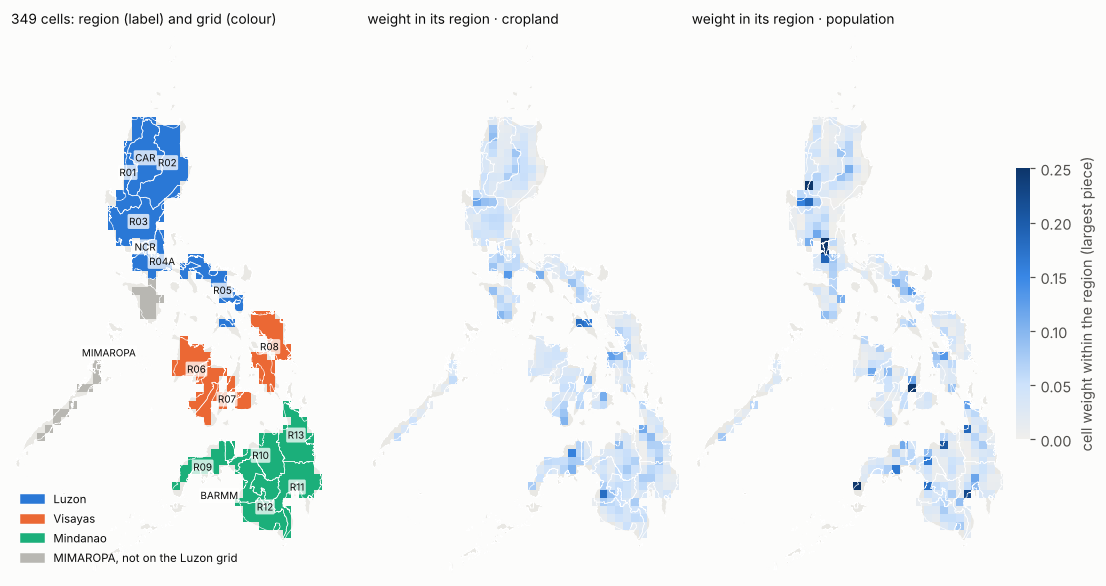

Share of each region's area, cropland and population inside the kept cells (the rest lies in coastal cells that ERA5 treats as sea):


code,NCR,CAR,R01,R02,R03,R04A,MIMAROPA,R05,R06,R07,R08,R09,R10,R11,R12,R13,BARMM
weights,,,,,,,,,,,,,,,,,
area,1.0,1.0,0.78,0.89,0.92,0.70,0.47,0.60,0.83,0.62,0.78,0.68,0.89,0.89,0.94,0.85,0.67
cropland,1.0,1.0,0.75,0.97,0.95,0.74,0.54,0.61,0.86,0.66,0.79,0.73,0.89,0.93,0.97,0.85,0.88
population,1.0,1.0,0.80,0.96,0.92,0.78,0.44,0.72,0.82,0.40,0.65,0.45,0.84,0.91,0.95,0.80,0.72


In [4]:
cells_tab = table("shared", "cells.csv").set_index("cell").loc[CELLS]
codes17 = list(GEO["r17"]["code"])
grid_of = {c: g for g, cs in cfg["grids"].items() for c in cs}
mim_in = cfg["sections"]["electricity"].get("mimaropa_in_luzon_grid", False)
GRID_COL = {"Luzon": 0, "Visayas": 1, "Mindanao": 2, "off-grid": 3}
cell_grid = cells_tab["region17_majority_population"].map(lambda c: "off-grid" if (c == "MIMAROPA" and not mim_in) else grid_of.get(c))
idx = cell_grid.map(GRID_COL).to_numpy(float)
pal = ListedColormap([S1, S2, S3, "#b8b7b2"])
Wc = D.W(WS_AGRI).max(0)
Wp = D.W(WS_POP).max(0)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 6.4), gridspec_kw={"wspace": 0.02})
draw_cells(axes[0], idx, pal, BoundaryNorm(np.arange(-0.5, 4.5), 4), title=f"{len(CELLS)} cells: region (label) and grid (colour)")
axes[0].legend(handles=[mpl.patches.Patch(color=pal(i), label=g if g != "off-grid" else "MIMAROPA, not on the Luzon grid")
                        for g, i in GRID_COL.items() if g != "off-grid" or not mim_in], loc="lower left", fontsize=7.5)
for c, g in GEO["r17"].set_index("code").to_crs(32651).centroid.to_crs(4326).items():
    axes[0].annotate(c, (g.x, g.y), fontsize=6.5, ha="center", va="center", color=INK,
                     bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
norm = Normalize(0, 0.25)
draw_cells(axes[1], Wc, BLUES, norm, title=f"weight in its region · {WS_AGRI.split('_')[1]}")
draw_cells(axes[2], Wp, BLUES, norm, title=f"weight in its region · {WS_POP.split('_')[1]}")
cbar(fig, axes[1:], BLUES, norm, "cell weight within the region (largest piece)", shrink=0.5)
plt.show()
if COVER is not None:
    cv = COVER[COVER["region_set"] == "r17"].pivot(index="code", columns="weights", values="share_captured_by_land_cells").loc[codes17]
    print("Share of each region's area, cropland and population inside the kept cells (the rest lies in coastal cells that ERA5 treats as sea):")
    display(cv.T.round(2))
    fb = COVER[COVER["fallback"]][["region_set", "weights", "source"]].drop_duplicates()
    if len(fb):
        print("NOTE — these weights fall back to area because the input file is missing:\n" + fb.to_string(index=False))

| Variable | | Units | Transform |
|---|---|---|---|
| T | mean 2 m temperature | °C | none |
| VPD | vapour pressure deficit, $e_s(T)-e_s(T_d)$ | kPa | none |
| P | precipitation | mm/month | Gamma |
| SM_RZ | root-zone soil moisture, 0–100 cm (swvl1–3, 7/21/72 cm) | m³/m³ | none |
| SM_DEEP | deep soil moisture, 100–289 cm (swvl4) | m³/m³ | none |
| PET, E | potential and actual evaporation (× −1) | mm/month | none |
| SPEI3 | 3-month P − PET, standardised per calendar month | std. units | none |
| RS | surface solar radiation | MJ m⁻² day⁻¹ | none |
| RO | runoff | mm/month | Gamma |

The hourly rows of Table 2 (TMAX, TMIN, extreme degree-days, hot days, dry days, longest dry spell, heavy-rain days, afternoon VPD) join as further variables once `scripts/02_hourly_metrics.py` has run. The count variables use an empirical normal-score transform.

## 3 · Pre-processing one column

The model is fitted separately for each **target calendar month**, because the teleconnections change with the season. For a target month, each column (one variable at one cell) has one value per year. Inside every training sample, the column is then:

1. **Transformed** to normal scores, $T_v$: a Gamma distribution is fitted for skewed, positive variables (rainfall, runoff), and the identity is used otherwise.
2. **Detrended**: a linear trend in the year is removed. The trend is the slow warming and drying of the record, which must not be credited to ENSO.
3. **Standardised** to unit variance.

The trend term $\mu + \zeta(t - t_{ref})$ is kept and used again at the end: Eq. 10 adds it back at $t^*$ = `period.t_star` (today's climate).

The example is rainfall in December at the cell with the most cropland in Central Luzon.

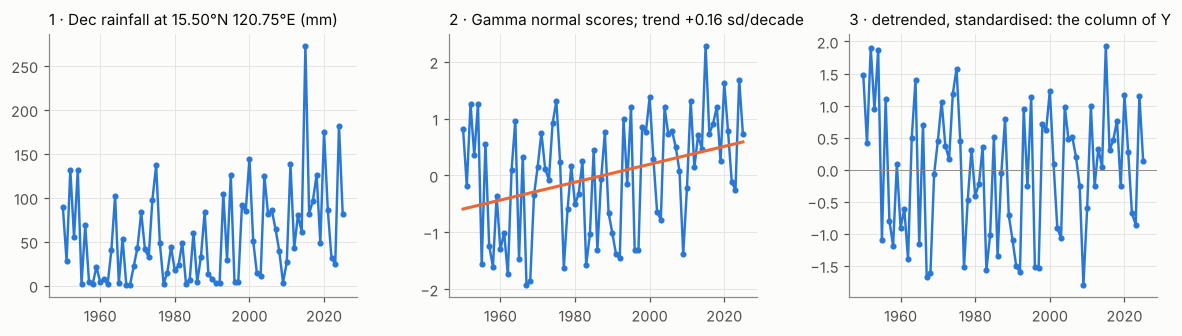

In [5]:
V_EX, M_EX = "P", 12
r03 = list(D.regions(WS_AGRI)[1]).index("R03")
j = int(np.argmax(D.W(WS_AGRI)[r03]))
years, Y, X = D.month_data(V_EX, M_EX)
pp, Ys = E.prep_y(Y, years, [C.PREDICTANDS[V_EX][3]] * Y.shape[1])
Z = pp.tf.forward(Y)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.1), gridspec_kw={"wspace": 0.3})
axes[0].plot(years, Y[:, j], color=S1, lw=1.6, marker="o", ms=3)
axes[0].set_title(f"1 · {MONTH[M_EX - 1]} rainfall at {CLAT[j]:.2f}°N {CLON[j]:.2f}°E (mm)")
axes[1].plot(years, Z[:, j], color=S1, lw=1.6, marker="o", ms=3)
tr = pp.mu[j] + pp.zeta[j] * (years - E.T_REF)
axes[1].plot(years, tr, color=S2, lw=2)
axes[1].set_title(f"2 · Gamma normal scores; trend {pp.zeta[j] * 10:+.2f} sd/decade")
axes[2].plot(years, Ys[:, j], color=S1, lw=1.6, marker="o", ms=3)
axes[2].axhline(0, color=MUTED, lw=0.6)
axes[2].set_title("3 · detrended, standardised: the column of Y")
plt.show()

## 4 · EOFs: the spatial patterns of the predictand

With one column per cell, $Y$ has a few hundred columns and about 75 rows (years). Neighbouring cells, and rainfall, soil moisture and runoff, move together, so fitting each column on its own would give noisy, inconsistent patterns (WMO-No. 1246, §1.5.1). $Y$ is therefore reduced to its leading empirical orthogonal functions (Eq. 8):

$$Y = USV^\top, \qquad Y \approx Z\Lambda^\top, \qquad Z = \sqrt{n-1}\,U_{[:,1:M_y]}, \qquad \Lambda = V_{[:,1:M_y]}S_{[1:M_y]}/\sqrt{n-1}.$$

The principal components $Z$ are uncorrelated with unit variance, and the loadings $\Lambda$ are maps. The maps show the loadings (the correlation of each cell with the component) of the first three EOFs of December rainfall, with the share of variance each explains and its correlation with the December RONI.

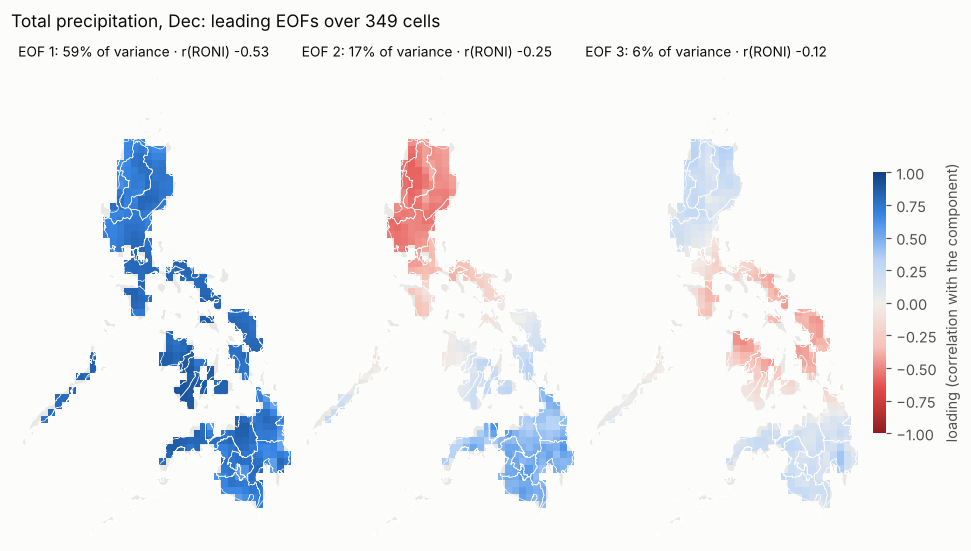

In [6]:
def eof_maps(var, month, n=3):
    years, Y, X = D.month_data(var, month)
    _, Ys = E.prep_y(Y, years, [C.PREDICTANDS[var][3]] * Y.shape[1])
    U, S, Vt = np.linalg.svd(Ys, full_matrices=False)
    pcs = np.sqrt(len(Ys) - 1) * U[:, :n]
    load = Vt[:n].T * S[:n] / np.sqrt(len(Ys) - 1)
    x = X["sync"][:, 0]
    fig, axes = plt.subplots(1, n, figsize=(3.6 * n + 1, 5.6), gridspec_kw={"wspace": 0.02})
    norm = TwoSlopeNorm(0, -1, 1)
    for i in range(n):
        if load[:, i].mean() < 0:
            pcs[:, i] *= -1; load[:, i] *= -1
        r = np.corrcoef(pcs[:, i], x)[0, 1]
        draw_cells(axes[i], load[:, i], RED_BLUE, norm,
                   title=f"EOF {i + 1}: {100 * S[i] ** 2 / (S ** 2).sum():.0f}% of variance · r(RONI) {r:+.2f}")
    cbar(fig, axes, RED_BLUE, norm, "loading (correlation with the component)", shrink=0.55)
    fig.suptitle(f"{LONG[var]}, {MONTH[month - 1]}: leading EOFs over {Ys.shape[1]} cells", x=0.12, ha="left", y=0.97)
    plt.show()


eof_maps("P", 12)

The first EOF of December rainfall has the same sign almost everywhere: most of the year-to-year variance is a country-wide wet or dry month. Its component is anti-correlated with the RONI: El Niño years sit in the dry phase of this pattern, which is the El Niño drying of the boreal winter. Blue is drawn as "wetter in the positive phase". The later EOFs are contrasts between parts of the country, such as the east-facing coasts of the north-east monsoon against the west. The model keeps $M_y$ of them, between 1 and 6, chosen by cross-validation.

## 5 · CCA: from the indices to the patterns, and back to physical units

Canonical correlation analysis finds the pairs of weights $(a_\mu, b_\mu)$ for which the index combination $Xa_\mu$ and the EOF combination $Zb_\mu$ are most correlated; $\rho_\mu$ is the canonical correlation. With two to four predictors there are at most $M_c \le 2$ useful pairs. The prediction for a standardised predictor vector $\tilde x$ is (Eq. 9)

$$\hat z(\tilde x) = \sum_{\mu=1}^{M_c} \rho_\mu\,(a_\mu^\top \tilde x)\,b_\mu, \qquad \hat y(\tilde x) = \Lambda\,\hat z(\tilde x) \equiv G\,\tilde x,$$

and every cell goes back to physical units with its own transform, trend and spread (Eq. 10):

$$W_{v,i}(x, e) = T_v^{-1}\!\big(\mu_i + \zeta_i\,(t^* - t_{ref}) + \sigma_i\,[\hat y_i(\tilde x) + e_i]\big).$$

The residual $e$ is zero for the deterministic response and a historical residual map in the simulation (§8). The maps show the fitted response to a sustained +1 °C anomaly of each index (the same value in the target month and in the lagged month, when the model uses both), against a neutral month, in today's climate.

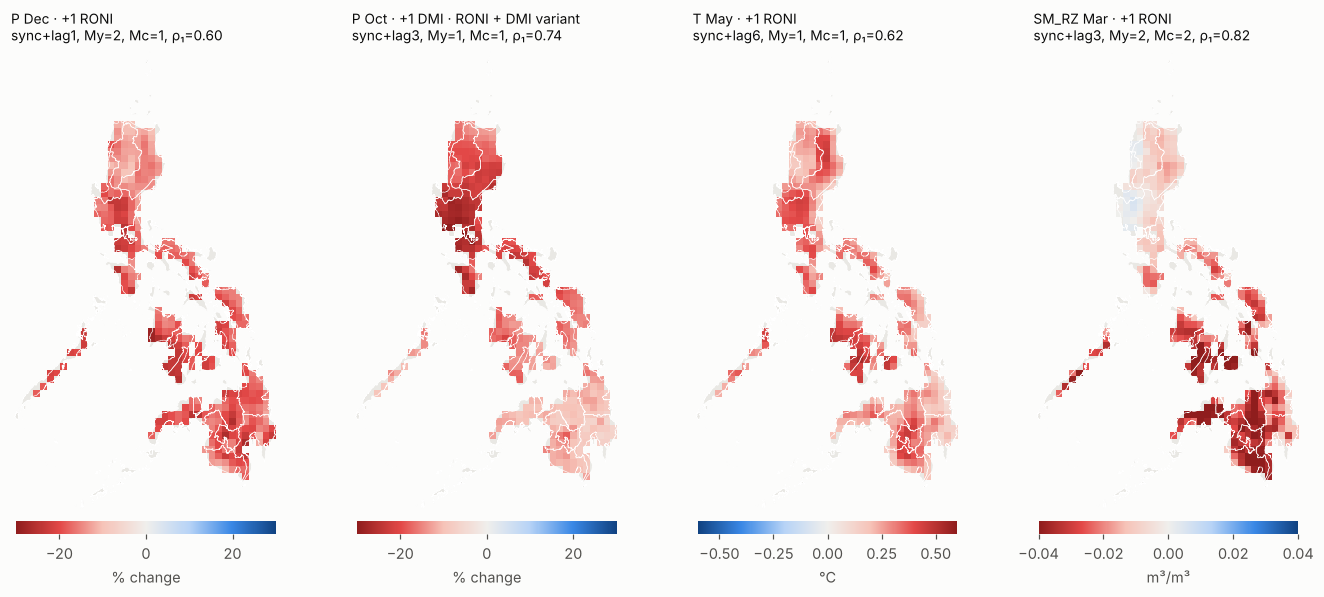

In [7]:
def response_maps(items):
    fig, axes = plt.subplots(1, len(items), figsize=(3.7 * len(items) + 1, 5.8), gridspec_kw={"wspace": 0.05})
    for ax, (var, month, which, vmax) in zip(axes, items):
        mdl, note = MODELS[(var, month)], ""
        if which not in mdl.predictors:
            if MODELS_JOINT is None:
                ax.set_axis_off(); ax.set_title(f"{var} {MONTH[month - 1]} · +1 {which.upper()}\n(fit the roni_dmi variant to see it)", fontsize=9)
                continue
            mdl, note = MODELS_JOINT[(var, month)], " · RONI + DMI variant"
        x1 = np.zeros(len(mdl.x_names()))
        for k, nm in enumerate(mdl.x_names()):
            if nm.startswith(which):
                x1[k] = 1.0
        t = cfg["period"]["t_star"]
        w1, w0 = mdl.physical(x1, t)[0], mdl.physical(np.zeros_like(x1), t)[0]
        pct = C.PREDICTANDS[var][3] == "gamma" or UNITS[var] == "mm/month"
        val = 100 * (w1 - w0) / w0 if pct else w1 - w0
        cmap = RED_BLUE if var in ("P", "SM_RZ", "SM_DEEP", "RO", "SPEI3", "E") else BLUE_RED
        norm = TwoSlopeNorm(0, -vmax, vmax)
        draw_cells(ax, val, cmap, norm, title=f"{var} {MONTH[month - 1]} · +1 {which.upper()}{note}\n"
                                              f"{mdl.lagset}, My={mdl.My}, Mc={mdl.Mc}, ρ₁={mdl.rho[0]:.2f}")
        cb = cbar(fig, ax, cmap, norm, "% change" if pct else UNITS[var], orientation="horizontal", shrink=0.8, pad=0.02, fraction=0.04)
    plt.show()


response_maps([("P", 12, "roni", 30), ("P", 10, "dmi", 30), ("T", 5, "roni", 0.6), ("SM_RZ", 3, "roni", 0.04)])

Read the maps as "what one more degree of the index does to this month, everything else equal":

* An El Niño (+1 RONI) dries December almost everywhere.
* A positive IOD dries October, mainly in the west and south (RONI + DMI variant, RONI held fixed).
* The warming that follows an El Niño winter shows in May temperature.
* Soil moisture integrates the dry months, so the El Niño signal in March soil moisture is broad.

Because every cell keeps its own transform, a rainfall change is a percentage of that cell's normal, not the same number of millimetres everywhere.

## 6 · Choosing the configuration by cross-validation

Three choices are left open for each variable and target month:

* $M_y \in \{1,\dots,6\}$, the number of predictand EOFs;
* $M_c \in \{1, 2\}$, the number of canonical pairs;
* the lags: the target month only, or the target month together with the indices 1, 3 or 6 months earlier.

All of them are scored by **leave-5-years-out cross-validation**. Each year is predicted by a model fitted without it and without the two years on either side, and the transform, trend, EOFs and CCA are all re-estimated in every fold. The configuration with the highest mean cross-validated Spearman correlation over the cells is kept. The model is then refitted on all years, and the cross-validated residual maps are stored for the simulation.

The heat map shows the score of every configuration for December rainfall; the tables count the choices over all variables and months.

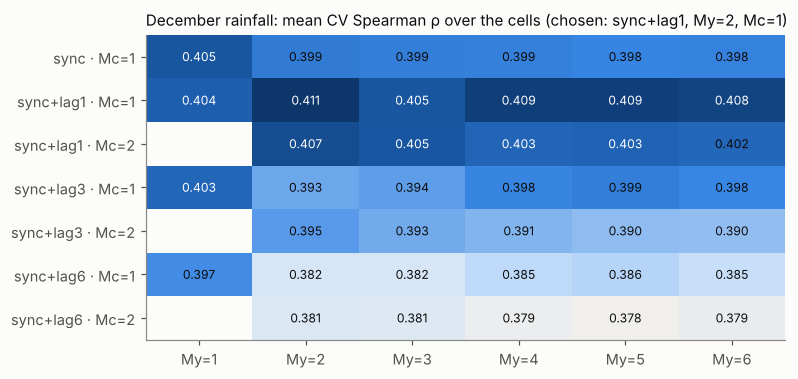

Chosen My (count over variables x months): {1: 38, 2: 33, 3: 20, 4: 17, 5: 6, 6: 6}
Chosen Mc: {1: 61, 2: 59} · lags: {'sync+lag6': 44, 'sync+lag3': 40, 'sync+lag1': 24, 'sync': 12}


month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
var,,,,,,,,,,,,
T,3,6,3,6,6,1,3,6,6,6,1,1
VPD,1,1,3,3,6,6,6,6,3,·,1,3
P,6,1,3,6,6,6,3,1,3,3,·,1
SM_RZ,6,1,3,3,6,6,6,3,6,3,·,·
SM_DEEP,6,1,3,3,6,6,6,6,6,3,6,1
PET,3,1,3,6,6,6,3,1,3,3,·,1
E,3,1,3,3,6,1,3,·,3,·,·,6
SPEI3,6,1,3,3,6,6,6,3,6,3,3,1
RS,3,1,3,6,6,1,3,1,3,3,·,1


In [8]:
sc = pd.Series(DIAG[("P", 12)]["scores"])
H = sc.rename_axis(["lags", "My", "Mc"]).unstack(["My"])
fig, ax = plt.subplots(figsize=(7.5, 3.6))
im = ax.imshow(H.values, cmap=BLUES, aspect="auto")
for i in range(H.shape[0]):
    for k in range(H.shape[1]):
        v = H.values[i, k]
        if np.isfinite(v):
            ax.text(k, i, f"{v:.3f}", ha="center", va="center", fontsize=8, color="white" if v > np.nanquantile(H.values, 0.7) else INK)
best = sc.idxmax()
ax.set_xticks(range(H.shape[1]), [f"My={c}" for c in H.columns]); ax.set_yticks(range(H.shape[0]), [f"{a} · Mc={b}" for a, b in H.index])
ax.grid(False)
ax.set_title(f"December rainfall: mean CV Spearman ρ over the cells (chosen: {best[0]}, My={best[1]}, Mc={best[2]})")
plt.show()
print("Chosen My (count over variables x months):", CONFIGS["My"].value_counts().sort_index().to_dict())
print("Chosen Mc:", CONFIGS["Mc"].value_counts().sort_index().to_dict(), "· lags:", CONFIGS["lagset"].value_counts().to_dict())
display(CONFIGS.pivot(index="var", columns="month", values="lagset").replace({"sync": "·", "sync+lag1": "1", "sync+lag3": "3", "sync+lag6": "6"}).loc[VARS]
        .rename(columns=dict(enumerate(MONTH, 1))).style.set_caption("· = target month only; 1, 3, 6 = lag (months) used with it"))

The differences between neighbouring configurations are small, so the choice matters less than it might seem; §7 measures how much the search for the best configuration flatters the score (nested cross-validation).

## 7 · Hindcast skill

All scores are computed on **cross-validated hindcasts**. These are predictions for each past year from a model that never saw it.

The cell predictions are converted to physical units and averaged with each section's weights. Each regional series is then standardised with the regional transform and trend of the same training sample, so the model is scored on exactly what Stage 2 receives.

The scores follow WMO-No. 1246:

| Score | What it measures | No skill |
|---|---|---|
| Spearman ρ | rank correlation of hindcast and observation | 0 |
| % significant | share of region–months with ρ significant at a 10% false-discovery rate (Benjamini–Hochberg, per variable) | — |
| 2AFC | probability of telling the wetter (warmer) of two years apart | 0.5 |
| RPSS | ranked probability skill score for the three terciles, against climatology | 0 |
| CRPSS | continuous ranked probability skill of the full predictive sample (hindcast plus residuals, built like the simulation) | 0 |
| coverage | share of years inside the sample's 10–90% range | 80% when calibrated |

**Nested cross-validation** is the honest score. An outer loop holds out 5-year blocks, and the configuration of §6 is chosen again on the remaining years only, so the score is charged for the configuration search.

In [9]:
order = SUMMARY[SUMMARY["weights"] == WS_AGRI].set_index("var")["rho_nested" if NESTED else "rho_cv"].sort_values(ascending=False).index
cols = {}
for ws in F.all_weight_sets(cfg):
    s = SUMMARY[SUMMARY["weights"] == ws].set_index("var")
    cols[f"ρ · {ws}"] = s["rho_nested" if NESTED else "rho_cv"]
s = SUMMARY[SUMMARY["weights"] == WS_AGRI].set_index("var")
cols["ρ · cells"] = s["rho_cells_nested" if NESTED else "rho_cells_cv"]
cols["% signif."] = s["pct_significant"]
cols["2AFC"] = s["two_afc"]
cols["RPSS"] = s["rpss"]
if "crpss" in s:
    cols["CRPSS"] = s["crpss"]; cols["coverage %"] = s["coverage_10_90"]
T7 = pd.DataFrame(cols).loc[order]
T7.insert(0, "variable", [LONG[v] for v in T7.index])
print(f"Hindcast skill, mean over regions and target months ({BEST} cross-validation); "
      f"probabilistic scores with the {WS_AGRI} weights")
display(T7.style.format({c: "{:.3f}" for c in T7.columns if c not in ("variable", "% signif.", "coverage %")} |
                        {"% signif.": "{:.0f}", "coverage %": "{:.0f}"}).background_gradient(cmap=BLUES, subset=[c for c in T7.columns if c.startswith("ρ")], vmin=0, vmax=0.6))

Hindcast skill, mean over regions and target months (nested cross-validation); probabilistic scores with the r16_cropland weights


,variable,ρ · r16_cropland,ρ · r16_area,ρ · r17_population,ρ · r17_area,ρ · cells,% signif.,2AFC,RPSS,CRPSS,coverage %
var,,,,,,,,,,,
SPEI3,"Climatic water balance, 3-month P - PET, standardised",0.506,0.506,0.505,0.501,0.462,92,0.680,0.185,0.163,79
RO,Runoff,0.434,0.431,0.430,0.424,0.387,83,0.652,0.151,0.128,78
SM_DEEP,"Deep soil moisture, 100-289 cm",0.431,0.450,0.405,0.432,0.402,87,0.650,0.147,0.119,79
SM_RZ,"Root-zone soil moisture, 0-100 cm",0.429,0.434,0.419,0.426,0.376,83,0.651,0.154,0.135,78
PET,Potential evaporation,0.383,0.380,0.380,0.377,0.358,73,0.635,0.128,0.114,78
P,Total precipitation,0.361,0.359,0.357,0.352,0.325,77,0.626,0.102,0.092,79
RS,Surface solar radiation downwards,0.333,0.334,0.332,0.331,0.320,72,0.617,0.106,0.088,78
VPD,Vapour pressure deficit,0.318,0.311,0.312,0.310,0.278,62,0.611,0.095,0.081,78
T,Mean 2 m temperature,0.263,0.253,0.258,0.253,0.228,47,0.591,0.059,0.048,78


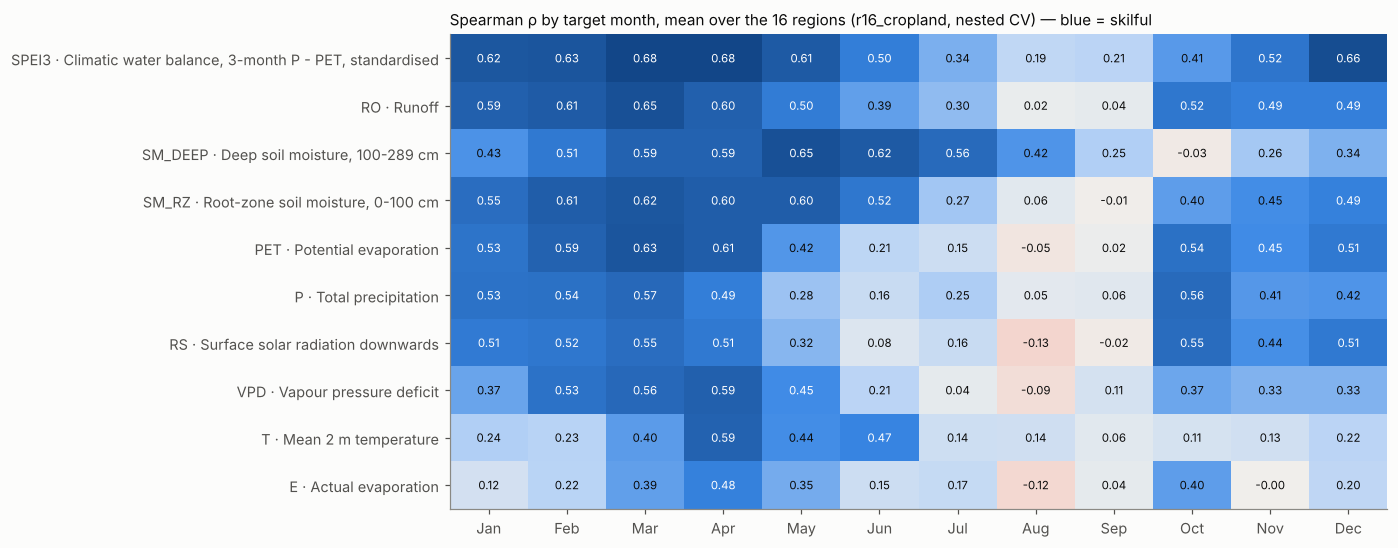

In [10]:
A = SK[WS_AGRI]
A = A[A["cv"] == BEST].pivot_table(index="var", columns="month", values="spearman", aggfunc="mean").loc[order]
fig, ax = plt.subplots(figsize=(11, 0.42 * len(A) + 1.4))
norm = TwoSlopeNorm(0, -0.7, 0.7)
ax.imshow(A.values, cmap=RED_BLUE, norm=norm, aspect="auto")
for i in range(A.shape[0]):
    for k in range(A.shape[1]):
        v = A.values[i, k]
        ax.text(k, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="white" if abs(v) > 0.45 else INK)
ax.set_xticks(range(12), MONTH); ax.set_yticks(range(len(A)), [f"{v} · {LONG[v]}" for v in A.index]); ax.grid(False)
ax.set_title(f"Spearman ρ by target month, mean over the 16 regions ({WS_AGRI}, {BEST} CV) — blue = skilful")
plt.show()

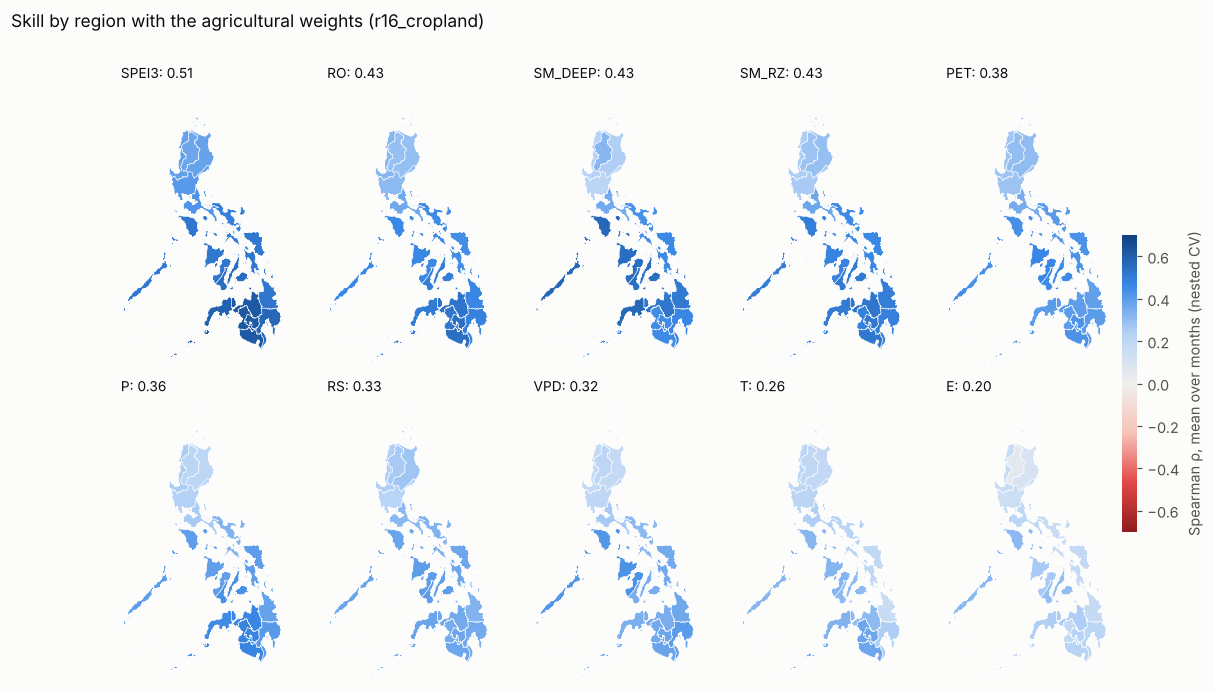

In [11]:
def skill_maps(ws, rs, vars_, title):
    t = SK[ws][SK[ws]["cv"] == BEST]
    n = len(vars_)
    ncol = min(5, n)
    fig, axes = plt.subplots(math.ceil(n / ncol), ncol, figsize=(2.75 * ncol + 0.6, 3.5 * math.ceil(n / ncol)), squeeze=False,
                             gridspec_kw={"wspace": 0.02, "hspace": 0.12})
    norm = TwoSlopeNorm(0, -0.7, 0.7)
    for ax, v in zip(axes.flat, vars_):
        r = t[t["var"] == v].groupby("code")["spearman"].mean()
        draw_regions(ax, r, RED_BLUE, norm, rs=rs, title=f"{v}: {r.mean():.2f}")
    for ax in list(axes.flat)[n:]:
        ax.set_axis_off()
    cbar(fig, axes, RED_BLUE, norm, f"Spearman ρ, mean over months ({BEST} CV)", shrink=0.5)
    fig.suptitle(title, x=0.08, ha="left")
    plt.show()


skill_maps(WS_AGRI, "r16", list(order), f"Skill by region with the agricultural weights ({WS_AGRI})")

**On the grid itself.** Cell series are noisier than regional averages, so cell skill is lower than regional skill. What matters is where it holds up. These maps show the cross-validated Spearman correlation at each cell, averaged over the target months. Averaging over a region raises the skill because it removes local, unpredictable weather (WMO-No. 1246, §2.6).

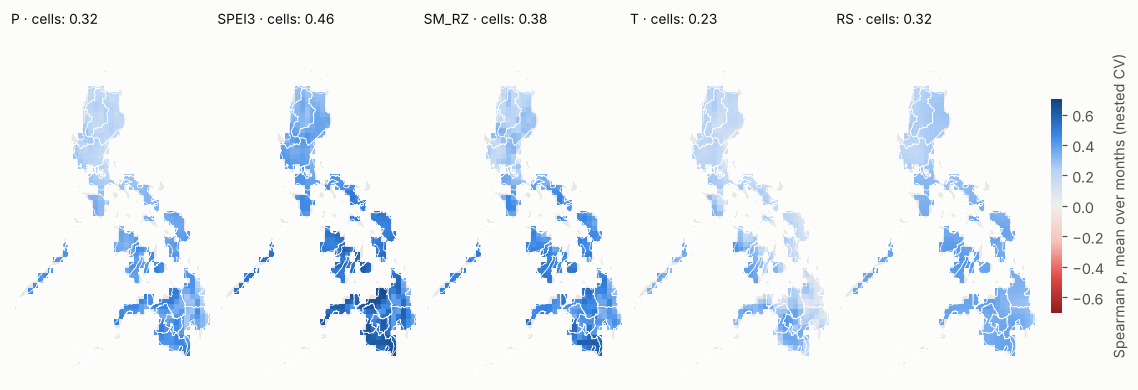

In [12]:
show = [v for v in ("P", "SPEI3", "SM_RZ", "T", "RS") if v in VARS]
fig, axes = plt.subplots(1, len(show), figsize=(2.75 * len(show) + 0.6, 4.2), gridspec_kw={"wspace": 0.02})
norm = TwoSlopeNorm(0, -0.7, 0.7)
col = "rho_nested" if NESTED else "rho_cv"
for ax, v in zip(axes, show):
    c = CELLSK[CELLSK["var"] == v].groupby("cell")[col].mean().reindex(CELLS)
    draw_cells(ax, c.values, RED_BLUE, norm, title=f"{v} · cells: {c.mean():.2f}")
cbar(fig, axes, RED_BLUE, norm, f"Spearman ρ, mean over months ({BEST} CV)", shrink=0.6)
plt.show()

### Electricity and labour: temperature on the 17 population-weighted regions

Electricity uses the Stage 1 response of monthly mean temperature in Eq. 3, and labour compares it with its own panel regression (§11.1 of the labour note). The heat map shows the temperature skill by region and month with population weights, NCR included. NCR is covered by the same grid fit as the other regions, through its population-weighted cells, so no separate regression is needed.

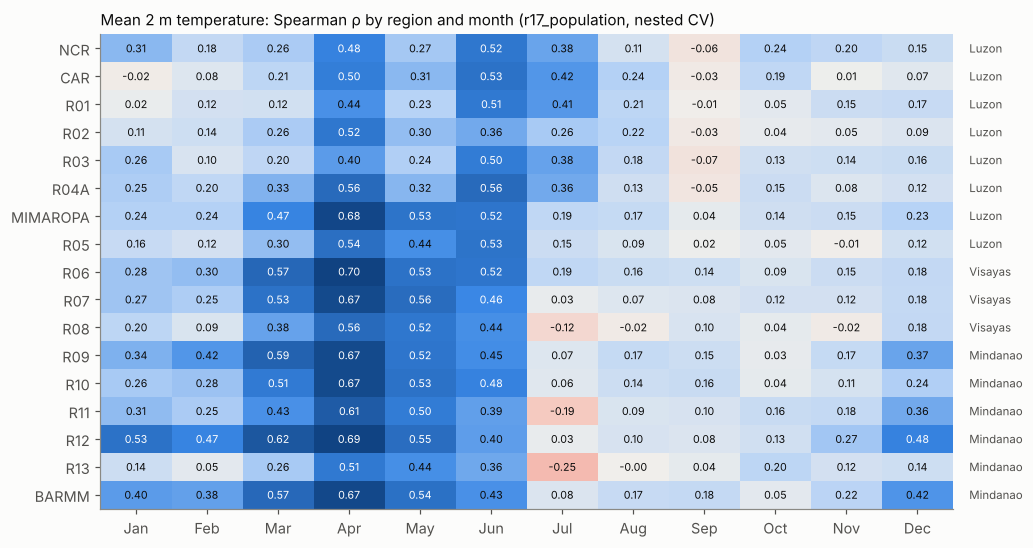

In [13]:
t = SK[WS_POP][(SK[WS_POP]["cv"] == BEST) & (SK[WS_POP]["var"] == "T")]
H = t.pivot_table(index="code", columns="month", values="spearman").loc[codes17]
fig, ax = plt.subplots(figsize=(10, 5.6))
norm = TwoSlopeNorm(0, -0.7, 0.7)
ax.imshow(H.values, cmap=RED_BLUE, norm=norm, aspect="auto")
for i in range(H.shape[0]):
    for k in range(H.shape[1]):
        v = H.values[i, k]
        ax.text(k, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.45 else INK)
ax.set_xticks(range(12), MONTH); ax.set_yticks(range(len(H)), H.index); ax.grid(False)
grid_of = {c: g for g, cs in cfg["grids"].items() for c in cs}
for i, c in enumerate(H.index):
    ax.annotate(grid_of.get(c, ""), (11.6, i), xytext=(6, 0), textcoords="offset points", va="center", fontsize=7.5, color=INK2,
                annotation_clip=False)
ax.set_title(f"Mean 2 m temperature: Spearman ρ by region and month ({WS_POP}, {BEST} CV)")
plt.show()

### How much does the configuration search flatter the score, and does the joint model do better?

* **Plain vs nested.** Plain cross-validation scores the configuration that was chosen on the same cross-validated predictions, so it is slightly optimistic. The nested score is the one to quote.
* **Per variable vs joint.** The text of §3.3.3 (Eq. 8) puts every variable's columns side by side in one EOF–CCA. The scripts fit one model per variable, so each variable keeps its own patterns, lags and number of modes, and run the joint model as a check.

In [14]:
rows = []
for v in order:
    t = SK[WS_AGRI][SK[WS_AGRI]["var"] == v]
    r = {"variable": v, "plain CV": t[t["cv"] == "plain"]["spearman"].mean()}
    if NESTED:
        r["nested CV"] = t[t["cv"] == "nested"]["spearman"].mean()
        r["optimism"] = r["plain CV"] - r["nested CV"]
    if JOINT is not None and v in set(JOINT["var"]):
        j = JOINT[JOINT["var"] == v]
        r["joint model (plain CV)"] = j["joint_regional_rho"].mean()
        r["joint − per variable"] = j["delta_regional"].mean()
    rows.append(r)
display(pd.DataFrame(rows).set_index("variable").style.format("{:+.3f}").set_caption(f"Mean Spearman ρ on {WS_AGRI}"))

,plain CV,nested CV,optimism,joint model (plain CV),joint − per variable
variable,,,,,
SPEI3,+0.508,+0.506,+0.002,+0.490,-0.018
RO,+0.448,+0.434,+0.015,+0.441,-0.008
SM_DEEP,+0.455,+0.431,+0.023,+0.416,-0.038
SM_RZ,+0.446,+0.429,+0.017,+0.441,-0.005
PET,+0.405,+0.383,+0.022,+0.402,-0.003
P,+0.377,+0.361,+0.016,+0.369,-0.008
RS,+0.365,+0.333,+0.031,+0.359,-0.006
VPD,+0.342,+0.318,+0.024,+0.347,+0.004
T,+0.312,+0.263,+0.049,+0.272,-0.040


### Is the spread right? Probabilistic hindcasts

Stage 2 receives many simulated weather paths, not one number, so the spread matters as much as the centre. Inside the nested cross-validation, each held-out year gets a predictive sample built exactly like the simulation: the prediction plus the cross-validated residual map of every training year. The sample is built at the cells and averaged over the region.

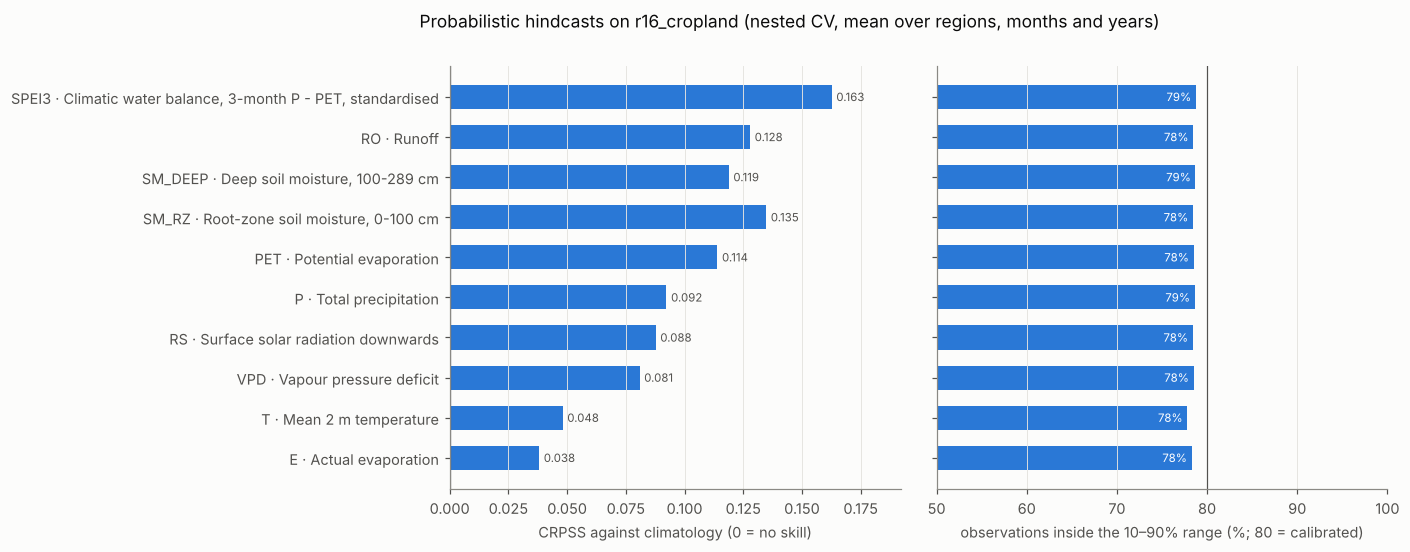

In [15]:
if PROB is not None:
    p = PROB[PROB["weights"] == WS_AGRI]
    g = p.groupby("var")
    PT = pd.DataFrame({"CRPSS": 1 - g["crps"].mean() / g["crps_clim"].mean(), "coverage": 100 * g["coverage_10_90"].mean()}).loc[order]
    fig, axes = plt.subplots(1, 2, figsize=(11, 0.32 * len(PT) + 1.8), sharey=True, gridspec_kw={"wspace": 0.08})
    y = np.arange(len(PT))[::-1]
    axes[0].barh(y, PT["CRPSS"], height=0.6, color=S1)
    axes[0].axvline(0, color=INK2, lw=0.8); axes[0].set_xlabel("CRPSS against climatology (0 = no skill)")
    axes[1].barh(y, PT["coverage"], height=0.6, color=S1)
    axes[1].axvline(80, color=INK2, lw=0.8); axes[1].set_xlim(50, 100); axes[1].set_xlabel("observations inside the 10–90% range (%; 80 = calibrated)")
    axes[0].set_yticks(y, [f"{v} · {LONG[v]}" for v in PT.index])
    for ax in axes:
        ax.grid(axis="y", visible=False)
    for yy, v in zip(y, PT["CRPSS"]):
        axes[0].annotate(f"{v:.3f}", (max(v, 0), yy), xytext=(3, 0), textcoords="offset points", va="center", fontsize=7.5, color=INK2)
    axes[0].set_xlim(min(0, PT["CRPSS"].min() * 1.2), PT["CRPSS"].max() * 1.18)
    for yy, v in zip(y, PT["coverage"]):
        axes[1].annotate(f"{v:.0f}%", (v, yy), xytext=(-3, 0), textcoords="offset points", va="center", ha="right", fontsize=7.5, color="white")
    fig.suptitle(f"Probabilistic hindcasts on {WS_AGRI} (nested CV, mean over regions, months and years)", x=0.1, ha="left")
    plt.show()

### Past events

Nested cross-validated hindcasts for months of strong El Niño and La Niña, against what happened, on the 16 agricultural regions. Both are standardised anomalies, so the colours compare directly; `r` is the correlation of the two maps across regions.

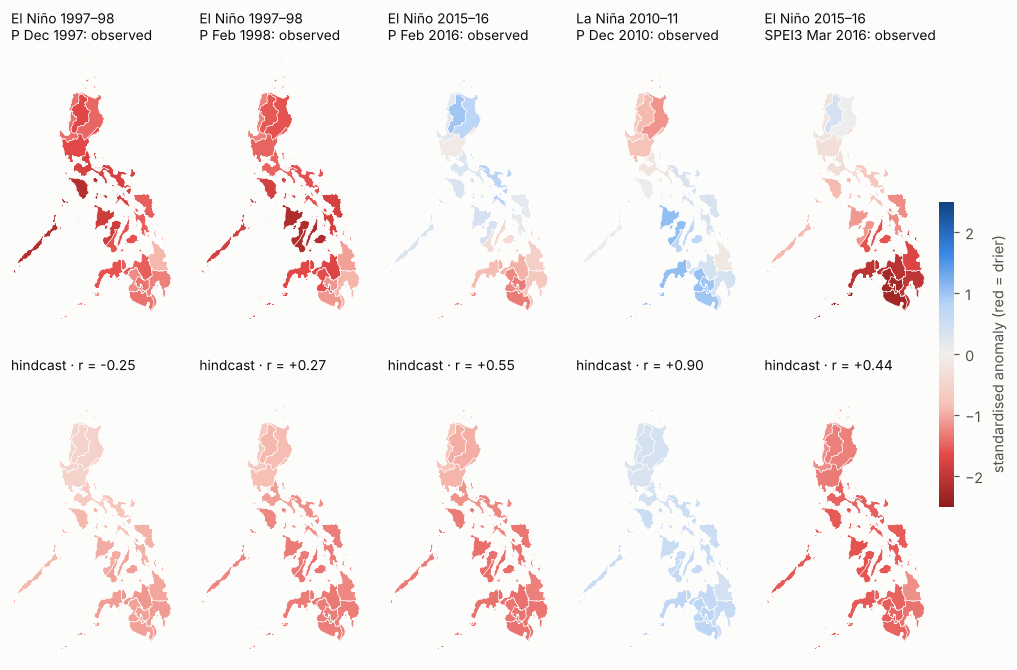

In [16]:
EVENTS = [("P", 1997, 12, "El Niño 1997–98"), ("P", 1998, 2, "El Niño 1997–98"), ("P", 2016, 2, "El Niño 2015–16"),
          ("P", 2010, 12, "La Niña 2010–11"), ("SPEI3", 2016, 3, "El Niño 2015–16")]
hc = HIND[HIND["weights"] == WS_AGRI]
pcol = "pred_nested" if "pred_nested" in hc else "pred_cv"
fig, axes = plt.subplots(2, len(EVENTS), figsize=(2.5 * len(EVENTS) + 0.6, 7.2), gridspec_kw={"wspace": 0.02, "hspace": 0.18})
norm = TwoSlopeNorm(0, -2.5, 2.5)
for k, (v, yr, m, lab) in enumerate(EVENTS):
    e = hc[(hc["var"] == v) & (hc["year"] == yr) & (hc["month"] == m)].set_index("code")
    if e.empty:
        axes[0, k].set_axis_off(); axes[1, k].set_axis_off(); continue
    cmap = RED_BLUE
    r = np.corrcoef(e["obs"], e[pcol])[0, 1]
    draw_regions(axes[0, k], e["obs"], cmap, norm, title=f"{lab}\n{v} {MONTH[m - 1]} {yr}: observed")
    draw_regions(axes[1, k], e[pcol], cmap, norm, title=f"hindcast · r = {r:+.2f}")
cbar(fig, axes, RED_BLUE, norm, "standardised anomaly (red = drier)", shrink=0.5)
plt.show()

In [17]:
# Key numbers, computed from the tables above
s = T7.iloc[:, 1]
print(f"• Best predicted ({WS_AGRI}): " + ", ".join(f"{v} {s[v]:.2f}" for v in s.index[:3]) +
      f"; least: " + ", ".join(f"{v} {s[v]:.2f}" for v in s.index[-2:]) + ".")
for v in ("P", "T"):
    if v in A.index:
        top = A.loc[v].sort_values(ascending=False)
        print(f"• {v}: highest skill in " + ", ".join(f"{MONTH[m - 1]} ({top[m]:.2f})" for m in top.index[:4]) +
              f"; lowest in " + ", ".join(f"{MONTH[m - 1]} ({top[m]:.2f})" for m in top.index[-3:]) + ".")
if NESTED:
    opt = pd.DataFrame(rows).set_index("variable")["optimism"]
    print(f"• Selection optimism (plain − nested): {opt.min():+.3f} to {opt.max():+.3f}.")
if JOINT is not None:
    d = JOINT.groupby("var")["delta_regional"].mean()
    print(f"• Joint model minus one model per variable: {d.min():+.3f} to {d.max():+.3f} (mean ρ on {WS_AGRI}).")
d = SUMMARY.pivot(index="var", columns="weights", values="rho_nested" if NESTED else "rho_cv")
print("• Spread of the regional skill across weight sets (max − min, per variable): "
      f"{(d.max(axis=1) - d.min(axis=1)).min():.3f} to {(d.max(axis=1) - d.min(axis=1)).max():.3f}.")

• Best predicted (r16_cropland): SPEI3 0.51, RO 0.43, SM_DEEP 0.43; least: T 0.26, E 0.20.
• P: highest skill in Mar (0.57), Oct (0.56), Feb (0.54), Jan (0.53); lowest in Jun (0.16), Sep (0.06), Aug (0.05).
• T: highest skill in Apr (0.59), Jun (0.47), May (0.44), Mar (0.40); lowest in Nov (0.13), Oct (0.11), Sep (0.06).
• Selection optimism (plain − nested): +0.002 to +0.049.
• Joint model minus one model per variable: -0.040 to +0.004 (mean ρ on r16_cropland).
• Spread of the regional skill across weight sets (max − min, per variable): 0.003 to 0.045.


## 8 · From hindcasts to scenarios

For a climate-mode path $x^S$ (monthly RONI and DMI), Stage 1 produces simulated weather for every **historical block** $Y_b$:

$$W_{v,i,t}^{\,b}(x) = T_v^{-1}\!\Big(\mu_i + \zeta_i\,(t^*-t_{ref}) + \sigma_i\big[\hat y_i(\tilde x_t) + e_{i}(t - \Delta_b)\big]\Big),$$

where $e_i(t-\Delta_b)$ is the cross-validated residual of cell $i$ in the same calendar month, $\Delta_b$ years earlier.

* **Residuals.** Each draw uses the residual map of one historical year. It is the same for every cell, every variable and the neutral path. A path that spans two calendar years uses two consecutive historical years. This keeps the links between regions, between rainfall and temperature, and over time (§3.5).
* **Neutral path.** It is the same calculation with $x = 0$, so scenario minus neutral contains only ENSO and the IOD.
* **Trend.** It is evaluated at $t^*$, so both paths are in today's climate.
* **Aggregation.** The cells are averaged with each section's weights only after the back-transform.
* **Same blocks for all sections.** Electricity and labour use the same blocks, listed in `outputs/shared/blocks.csv`.

The path below is the one built by `scripts/helpers/make_path.py` from the latest C3S forecast.

In [18]:
eff = table("agriculture", "effects_16regions.csv")
if path is None or eff is None:
    print("Run python scripts/04_simulate.py to see the scenario.")
else:
    pth = path.set_index(pd.to_datetime(path["date"]))
    fig, ax = plt.subplots(figsize=(11, 2.8))
    for k, c, lab in (("roni", "#e34948", "RONI"), ("dmi", S1, "DMI")):
        ax.plot(pth.index, pth[k], color=c, lw=2, label=lab)
        if f"{k}_q10" in pth:
            ax.fill_between(pth.index, pth[f"{k}_q10"], pth[f"{k}_q90"], color=c, alpha=0.15, lw=0)
    if (pth["roni_source"] == "forecast").any():
        fc = pth.index[pth["roni_source"] == "forecast"].min()
        ax.axvline(fc, color=MUTED, lw=0.8, ls="--")
        ax.annotate("C3S forecast →", (fc, ax.get_ylim()[1]), xytext=(4, -10), textcoords="offset points", fontsize=8, color=INK2)
    ax.axhline(0, color=MUTED, lw=0.6); ax.set_ylabel("°C"); ax.legend(loc="upper left", ncol=2)
    ax.set_title("Scenario path: observed indices, then the median of the C3S members (band: 10–90% of members)")
    plt.show()
    eff["date"] = pd.to_datetime(eff["date"])
    eff["q"] = eff["date"].dt.to_period("Q").astype(str)
    nmon = eff.groupby("q")["date"].nunique()
    qs = [q for q in nmon.index if nmon[q] == 3]
    fig, axes = plt.subplots(2, len(qs), figsize=(2.4 * len(qs) + 0.8, 7), gridspec_kw={"wspace": 0.02, "hspace": 0.15}, squeeze=False)
    for row, (v, cmap, unit) in enumerate((("P", RED_BLUE, "% of neutral"), ("T", BLUE_RED, "°C"))):
        e = eff[eff["var"] == v]
        vals = {}
        for q in qs:
            g = e[e["q"] == q].groupby("code")
            vals[q] = 100 * g["effect_mean"].sum() / g["neutral_mean"].sum() if v == "P" else g["effect_mean"].mean()
        vmax = max(np.nanquantile(np.abs(pd.concat(vals.values())), 0.98), 1e-6)
        vmax = float(np.ceil(vmax * (0.1 if v == "P" else 10)) / (0.1 if v == "P" else 10))
        for k, q in enumerate(qs):
            draw_regions(axes[row, k], vals[q], cmap, TwoSlopeNorm(0, -vmax, vmax), title=f"{v} · {q}")
        cbar(fig, axes[row], cmap, TwoSlopeNorm(0, -vmax, vmax), f"{v}: scenario − neutral ({unit})", shrink=0.8)
    fig.suptitle("Expected effect of the path by quarter, mean over draws (agricultural weights)", x=0.08, ha="left")
    plt.show()

Run python scripts/04_simulate.py to see the scenario.


In [19]:
sim = table("agriculture", "simulated_monthly_16regions.csv")
if sim is not None:
    sim["date"] = pd.to_datetime(sim["date"])
    q = sim["date"].dt.to_period("Q").astype(str)
    pick = sorted(q.unique())[min(4, q.nunique() - 1)]
    s = sim[(q == pick) & (sim["code"] == "R03")].groupby(["path", "draw"])["P"].sum().unstack(0)
    fig, ax = plt.subplots(figsize=(7.5, 2.8))
    bins = np.linspace(0, s.values.max() * 1.02, 26)
    ax.hist(s["neutral"], bins=bins, color="#d6d5d0", label="neutral path")
    ax.hist(s["scenario"], bins=bins, histtype="step", color="#e34948", lw=2, label="scenario path")
    ax.set_xlabel(f"Central Luzon rainfall in {pick} (mm, one value per historical block)"); ax.set_ylabel("draws")
    ax.legend(); ax.grid(axis="x", visible=False)
    ax.set_title(f"Simulated weather: {len(s)} draws, each with the residuals of one historical block")
    plt.show()
    print(f"median {s['neutral'].median():.0f} mm (neutral) → {s['scenario'].median():.0f} mm (scenario); "
          f"P(below the neutral lower tercile) = {(s['scenario'] < s['neutral'].quantile(1 / 3)).mean():.2f}")

## 9 · Reading the results, and their limits

* **What the skill means.** The ENSO and IOD signal is strongest in the integrating water variables (SPEI-3, soil moisture, runoff) and in rainfall from October to April, when El Niño dries the Philippines. It is weak in rainfall during the south-west monsoon. Temperature skill peaks in April to June, after the El Niño winter. A low score for a variable or month means that Stage 1 will pass on little ENSO signal there, not that the weather does not matter for Stage 2.
* **Same regional answer, any weights.** Fitting on the cells and aggregating afterwards gives the same regional skill as fitting on regional averages (tested on the same data). It also lets one fit serve all three sets of weights. The weights change the regional skill by only a few hundredths.
* **Today's climate.** Trends are removed inside every training sample and added back at $t^*$, so slow warming is not credited to ENSO and every simulated year is in today's climate. Background climate change is added separately by SOAS in DEFINE-PH.
* **Limits.**
  * ERA5 before 1979 assimilates fewer observations.
  * ERA5 soil moisture does not see irrigation.
  * Cells on the coast are partly sea, so the share of a region's cropland or population inside the kept cells is below one (§2).
  * The empirical transform of the hourly counts cannot simulate values beyond the observed range.
  * The simulation keeps the observed spread of residuals, so it does not widen in strong events. The coverage in §7 shows how close to calibrated it is.